<a href="https://colab.research.google.com/github/anishkumarcs24/BIS/blob/main/Robot_Path_Planning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
pip install numpy matplotlib

Iteration: 1 Best Fitness: 10207.34
Iteration: 2 Best Fitness: 177.783
Iteration: 3 Best Fitness: 149.254
Iteration: 4 Best Fitness: 139.246
Iteration: 5 Best Fitness: 139.246
Iteration: 6 Best Fitness: 139.246
Iteration: 7 Best Fitness: 134.919
Iteration: 8 Best Fitness: 134.919
Iteration: 9 Best Fitness: 134.375
Iteration: 10 Best Fitness: 134.375
Iteration: 11 Best Fitness: 133.224
Iteration: 12 Best Fitness: 133.224
Iteration: 13 Best Fitness: 133.224
Iteration: 14 Best Fitness: 133.224
Iteration: 15 Best Fitness: 133.224
Iteration: 16 Best Fitness: 133.224
Iteration: 17 Best Fitness: 133.224
Iteration: 18 Best Fitness: 133.224
Iteration: 19 Best Fitness: 133.224
Iteration: 20 Best Fitness: 133.224
Iteration: 21 Best Fitness: 133.224
Iteration: 22 Best Fitness: 133.224
Iteration: 23 Best Fitness: 133.224
Iteration: 24 Best Fitness: 133.224
Iteration: 25 Best Fitness: 133.224
Iteration: 26 Best Fitness: 133.224
Iteration: 27 Best Fitness: 133.224
Iteration: 28 Best Fitness: 133.224


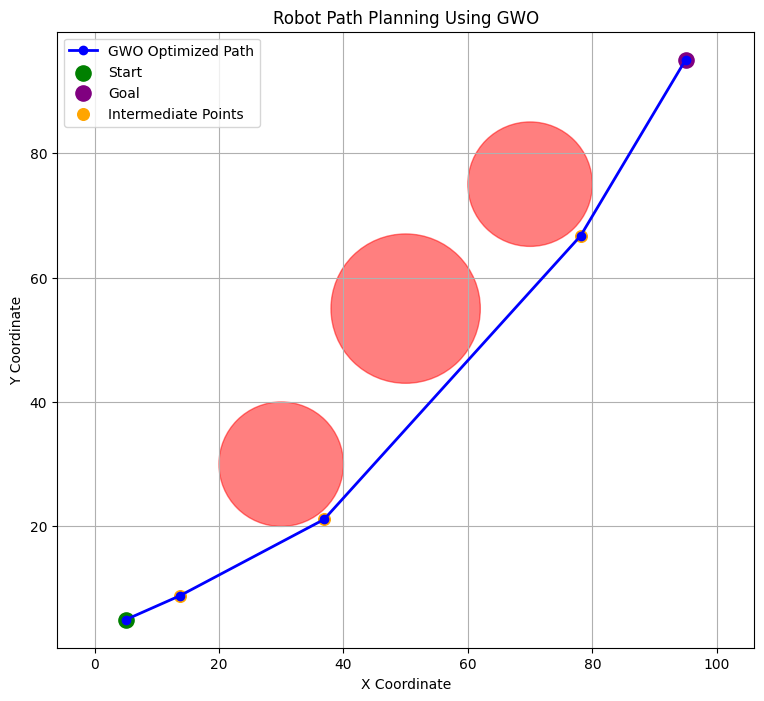

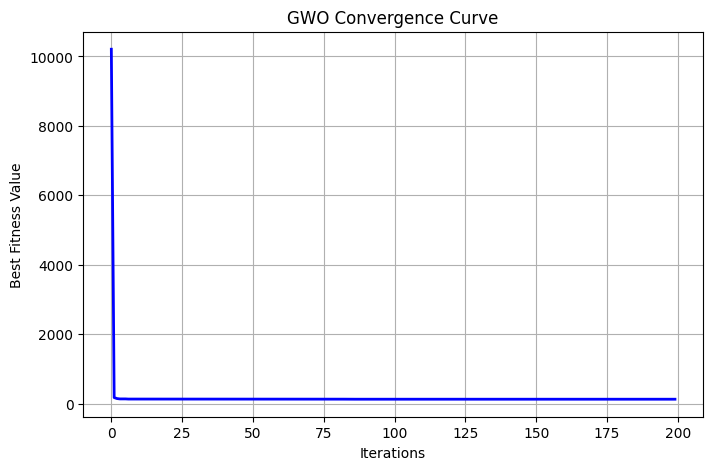

In [4]:

import numpy as np
import matplotlib.pyplot as plt
import time

# =====================================
# 1. ENVIRONMENT INITIALIZATION
# =====================================

START = np.array([5.0, 5.0])
GOAL = np.array([95.0, 95.0])

# Exactly three circular obstacles
OBSTACLES = [
    (30, 30, 10),
    (50, 55, 12),
    (70, 75, 10)
]

# =====================================
# 2. GWO PARAMETERS
# =====================================

N_WOLVES = 40
MAX_ITER = 200
N_POINTS = 3

LOWER = 5
UPPER = 95

PENALTY = 10000

DIM = N_POINTS * 2


# =====================================
# 3. COLLISION DETECTION
# =====================================

def collision(point):

    for ox, oy, radius in OBSTACLES:

        center = np.array([ox, oy])

        distance = np.linalg.norm(point - center)

        if distance <= radius + 1:
            return True

    return False


def segment_collision(p1, p2):

    for ox, oy, radius in OBSTACLES:

        center = np.array([ox, oy])

        direction = p2 - p1

        if np.dot(direction, direction) == 0:
            closest = p1
        else:
            t = np.dot(center - p1, direction) / np.dot(
                direction, direction
            )

            t = np.clip(t, 0, 1)

            closest = p1 + t * direction

        distance = np.linalg.norm(closest - center)

        if distance <= radius + 1:
            return True

    return False


# =====================================
# 4. FITNESS FUNCTION
# =====================================

def fitness(wolf):

    points = wolf.reshape(N_POINTS, 2)

    path = np.vstack((START, points, GOAL))

    # Calculate total path distance
    distance = np.sum(
        np.linalg.norm(np.diff(path, axis=0), axis=1)
    )

    penalty = 0

    # Check all path segments
    for i in range(len(path) - 1):

        if segment_collision(path[i], path[i + 1]):
            penalty += PENALTY

    return distance + penalty


# =====================================
# 5. INITIALIZE GRAY WOLVES
# =====================================

wolves = np.random.uniform(
    LOWER, UPPER, (N_WOLVES, DIM)
)

alpha = np.zeros(DIM)
beta = np.zeros(DIM)
delta = np.zeros(DIM)

alpha_score = float("inf")
beta_score = float("inf")
delta_score = float("inf")

best_history = []

start_time = time.time()


# =====================================
# 6. GRAY WOLF OPTIMIZATION
# =====================================

for iteration in range(MAX_ITER):

    # Evaluate all wolves
    for i in range(N_WOLVES):

        score = fitness(wolves[i])

        if score < alpha_score:

            delta_score = beta_score
            delta = beta.copy()

            beta_score = alpha_score
            beta = alpha.copy()

            alpha_score = score
            alpha = wolves[i].copy()

        elif score < beta_score:

            delta_score = beta_score
            delta = beta.copy()

            beta_score = score
            beta = wolves[i].copy()

        elif score < delta_score:

            delta_score = score
            delta = wolves[i].copy()

    # Decrease control parameter
    a = 2 - 2 * iteration / MAX_ITER

    # Update wolf positions
    for i in range(N_WOLVES):

        r1 = np.random.rand(DIM)
        r2 = np.random.rand(DIM)

        A1 = 2 * a * r1 - a
        C1 = 2 * r2

        D_alpha = np.abs(C1 * alpha - wolves[i])
        X1 = alpha - A1 * D_alpha

        r1 = np.random.rand(DIM)
        r2 = np.random.rand(DIM)

        A2 = 2 * a * r1 - a
        C2 = 2 * r2

        D_beta = np.abs(C2 * beta - wolves[i])
        X2 = beta - A2 * D_beta

        r1 = np.random.rand(DIM)
        r2 = np.random.rand(DIM)

        A3 = 2 * a * r1 - a
        C3 = 2 * r2

        D_delta = np.abs(C3 * delta - wolves[i])
        X3 = delta - A3 * D_delta

        wolves[i] = (X1 + X2 + X3) / 3

        wolves[i] = np.clip(
            wolves[i], LOWER, UPPER
        )

    best_history.append(alpha_score)

    print(
        "Iteration:", iteration + 1,
        "Best Fitness:", round(alpha_score, 3)
    )


# =====================================
# 7. FINAL OPTIMIZED PATH
# =====================================

best_points = alpha.reshape(N_POINTS, 2)

final_path = np.vstack((
    START,
    best_points,
    GOAL
))

total_distance = np.sum(
    np.linalg.norm(np.diff(final_path, axis=0), axis=1)
)

collision_free = all(
    not segment_collision(final_path[i], final_path[i+1])
    for i in range(len(final_path)-1)
)

execution_time = time.time() - start_time


# =====================================
# 8. DISPLAY RESULTS
# =====================================

print("\n========== GWO RESULTS ==========")

print("Optimized coordinates:")
print(final_path)

print("Total path length:", round(total_distance, 3))

print("Best fitness:", round(alpha_score, 3))

print("Collision free:", collision_free)

print("Execution time:", round(execution_time, 4), "seconds")


# =====================================
# 9. ROBOT PATH VISUALIZATION
# =====================================

plt.figure(figsize=(9, 8))

# Draw circular obstacles
for ox, oy, radius in OBSTACLES:

    circle = plt.Circle(
        (ox, oy),
        radius,
        color='red',
        alpha=0.5
    )

    plt.gca().add_patch(circle)

# Plot optimized path
plt.plot(
    final_path[:, 0],
    final_path[:, 1],
    'b-o',
    linewidth=2,
    markersize=6,
    label='GWO Optimized Path'
)

# Start and goal
plt.scatter(
    START[0], START[1],
    color='green',
    s=120,
    label='Start'
)

plt.scatter(
    GOAL[0], GOAL[1],
    color='purple',
    s=120,
    label='Goal'
)

# Intermediate points
plt.scatter(
    best_points[:, 0],
    best_points[:, 1],
    color='orange',
    s=70,
    label='Intermediate Points'
)

plt.xlim(0, 100)
plt.ylim(0, 100)

plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")

plt.title("Robot Path Planning Using GWO")

plt.grid(True)
plt.legend()
plt.axis('equal')
plt.show()


# =====================================
# 10. CONVERGENCE GRAPH
# =====================================

plt.figure(figsize=(8, 5))

plt.plot(
    best_history,
    color='blue',
    linewidth=2
)

plt.xlabel("Iterations")
plt.ylabel("Best Fitness Value")

plt.title("GWO Convergence Curve")

plt.grid(True)
plt.show()
